# 🎓 Computer vision, step by step: RinkIQ
Companion to **[`docs/LEARN.md`](../docs/LEARN.md)** and the app's **🎓 Learn CV** tab. Every section runs the
project's real code on a real NHL broadcast frame and **shows you the data** at that stage.

```
① pixels ─► ② detect (YOLO) ─► ③ track (IoU) ─► ④ undo the camera (ORB+RANSAC) ─► ⑤ homography ─► ⑥ speed ─► ⑦ pose ─► ✅ validate
```

In [1]:
import torch  # import torch first: on some Macs importing scikit-learn before torch crashes model loading
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
if Path.cwd().name == "notebooks":
    os.chdir("..")          # run from the repo root, where the model files live
sys.path.insert(0, ".")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from rinkiq import models, pipeline, simulate
from rinkiq.metrics import analyze
from rinkiq.pose import facing_from_keypoints
from rinkiq.rink import LANDMARKS, RINK_LENGTH, RINK_WIDTH, Calibration, pixels_to_rink

rgb = lambda bgr: cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
def show(images, titles=None, size=5):
    images = images if isinstance(images, list) else [images]
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.6))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles or [""] * len(images)):
        ax.imshow(im); ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.show()

## ① A video is a stack of images, and an image is a grid of numbers
(The sample clip is the model author's demo video, so it has their "Dots" labels drawn on it.)

600 frames at 60 fps
one frame: (720, 1280, 3) → (height, width, colour channels), dtype uint8
brightness of the top-left 6×6 pixels of that patch (white ice ≈ 200+, dark jersey ≈ 30–80):
[[40 40 39 38 47 68]
 [40 40 39 38 49 80]
 [40 39 37 38 47 81]
 [39 38 36 39 49 74]
 [39 38 33 37 45 54]
 [26 25 31 35 40 42]]


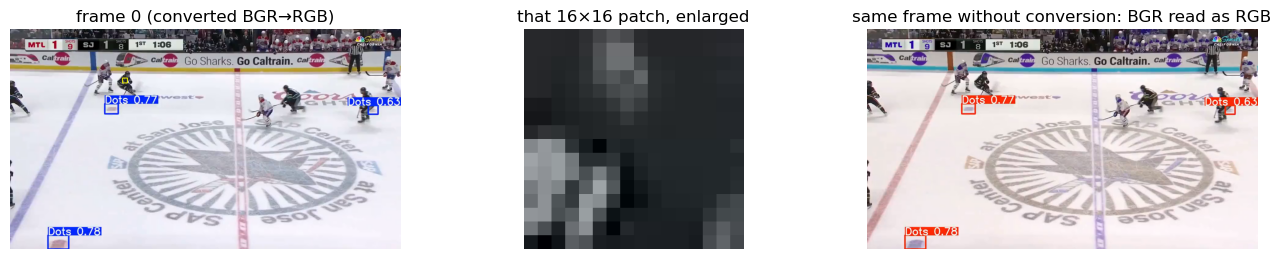

In [2]:
CLIP = "Broadcast clip · neutral zone (MTL vs SJ)"
clip = str(models.download_sample_clip(CLIP))          # from the Hockey-Vision repo on Hugging Face
info = pipeline.video_info(clip)
f0, f6, f30 = (pipeline.read_frame(clip, i) for i in (0, 6, 30))
print(f"{info['n_frames']} frames at {info['fps']:.0f} fps")
print("one frame:", f0.shape, "→ (height, width, colour channels), dtype", f0.dtype)
x, y = 368, 160
patch = f0[y:y + 16, x:x + 16]
print("brightness of the top-left 6×6 pixels of that patch (white ice ≈ 200+, dark jersey ≈ 30–80):")
print(patch[:6, :6].mean(axis=2).astype(int))
box = f0.copy(); cv2.rectangle(box, (x, y), (x + 16, y + 16), (0, 255, 255), 2)
show([rgb(box), cv2.resize(rgb(patch), (256, 256), interpolation=cv2.INTER_NEAREST), f0],
     ["frame 0 (converted BGR→RGB)", "that 16×16 patch, enlarged", "same frame without conversion: BGR read as RGB"], 4.5)

## ② Object detection: boxes, classes, confidence (YOLO)
The model was trained on NHL broadcasts by someone else and shared on Hugging Face: transfer learning, no
training here. Watch how the **confidence threshold** changes what you keep.

classes this model knows: ['goalie_a', 'goalie_b', 'puck', 'referee', 'team_a_player', 'team_b_player']
threshold 0.05 → 11 boxes
threshold 0.30 →  9 boxes
threshold 0.60 →  8 boxes
threshold 0.80 →  7 boxes


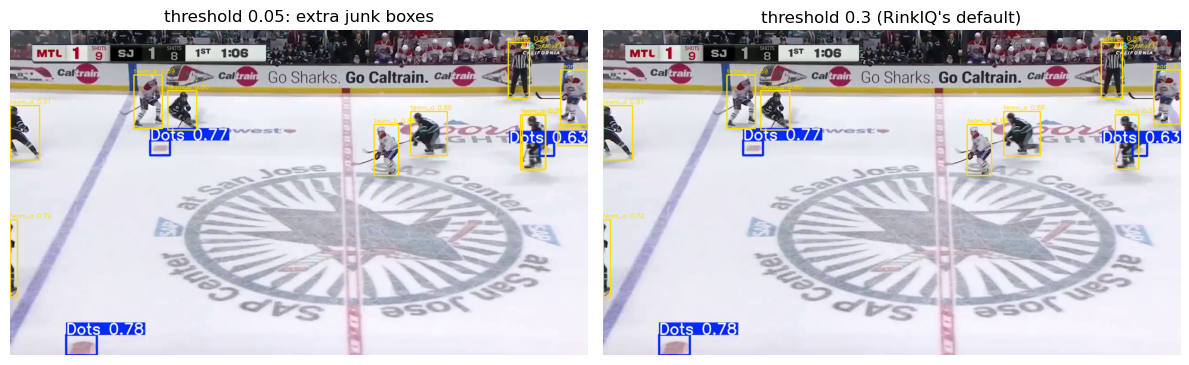

,x1,y1,x2,y2,conf,label
0,0.04,167.28,65.86,287.38,0.91,team_a_player
1,1103.52,27.15,1150.58,151.96,0.89,referee
2,274.08,99.19,337.65,218.33,0.89,team_b_player
3,806.87,209.80,860.29,322.27,0.88,team_b_player
4,887.49,180.34,968.64,278.53,0.88,team_a_player
5,1219.30,88.36,1278.43,208.69,0.85,team_b_player
6,349.85,134.98,413.80,221.14,0.80,team_a_player
7,0.00,420.72,16.66,592.55,0.72,team_a_player


In [3]:
player_model = models.load("player")
r = player_model(f0, conf=0.05, imgsz=960, verbose=False)[0]
det = pd.DataFrame([dict(x1=b[0], y1=b[1], x2=b[2], y2=b[3], conf=float(c), label=r.names[int(k)])
                    for b, c, k in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist())])
print("classes this model knows:", sorted(set(r.names.values())))
for t in [0.05, 0.3, 0.6, 0.8]:
    print(f"threshold {t:.2f} → {(det.conf >= t).sum():2d} boxes")

def draw(img, d, color=(0, 220, 255), label=True):
    out = img.copy()
    for b in d.itertuples():
        cv2.rectangle(out, (int(b.x1), int(b.y1)), (int(b.x2), int(b.y2)), color, 2)
        if label:
            cv2.putText(out, f"{b.label.replace('_player', '')} {b.conf:.2f}", (int(b.x1), int(b.y1) - 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)
    return out
show([rgb(draw(f0, det)), rgb(draw(f0, det[det.conf >= 0.3]))], ["threshold 0.05: extra junk boxes", "threshold 0.3 (RinkIQ's default)"], 6)
det[det.conf >= 0.3].round(2).head(8)

## ③ Tracking: is this the same player as a moment ago? (IoU)
**IoU** = overlap ÷ union of two boxes. Between frames 0.1 s apart, the same player's boxes overlap a lot.
Half a second later, fast skaters have moved on, which is why trackers like ByteTrack also predict motion.

0.1 s later (frame 6): median best IoU 0.67 · 78% of players easy to match (IoU > 0.5)
0.5 s later (frame 30): median best IoU 0.02 · 22% of players easy to match (IoU > 0.5)


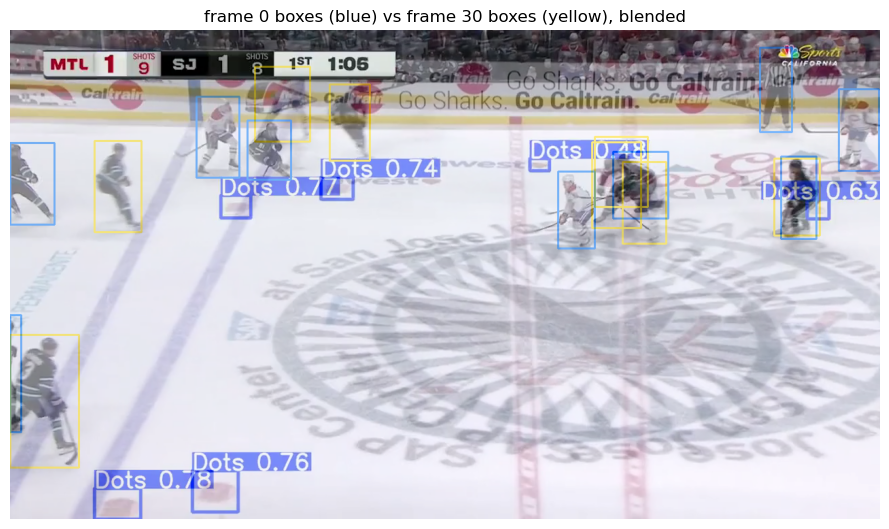

In [4]:
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

def boxes(frame):
    r = player_model(frame, conf=0.3, imgsz=960, verbose=False)[0]
    return pd.DataFrame(r.boxes.xyxy.tolist(), columns=["x1", "y1", "x2", "y2"]).assign(label="", conf=r.boxes.conf.tolist())

a = boxes(f0)
for name, later in [("0.1 s later (frame 6)", f6), ("0.5 s later (frame 30)", f30)]:
    b = boxes(later)
    best = [max(iou(ra, rb) for rb in b[["x1", "y1", "x2", "y2"]].to_numpy()) for ra in a[["x1", "y1", "x2", "y2"]].to_numpy()]
    print(f"{name}: median best IoU {np.median(best):.2f} · {np.mean(np.array(best) > 0.5):.0%} of players easy to match (IoU > 0.5)")
blend = cv2.addWeighted(draw(f0, a, (255, 120, 0), False), 0.5, draw(f30, boxes(f30), (0, 220, 255), False), 0.5, 0)
show([rgb(blend)], ["frame 0 boxes (blue) vs frame 30 boxes (yellow), blended"], 9)

## ④ The camera moves too: ORB keypoints + RANSAC
Find distinctive corners in both frames, match them, and let RANSAC find the one camera motion most matches
agree with. Wrong matches, like those on moving players, are voted out.

50 of 60 matches agree on one motion (RANSAC inliers) · they moved +144 px sideways (median)


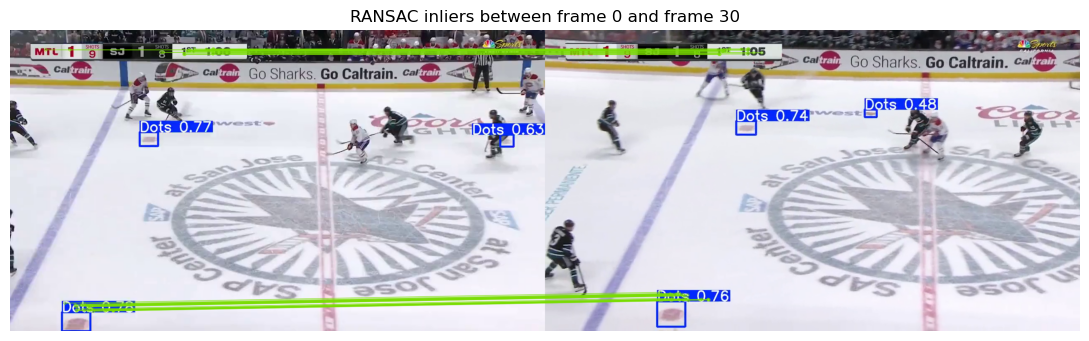

In [5]:
def camera_motion(mask=None):
    orb = cv2.ORB_create(800)
    k1, d1 = orb.detectAndCompute(cv2.cvtColor(f0, cv2.COLOR_BGR2GRAY), mask)
    k2, d2 = orb.detectAndCompute(cv2.cvtColor(f30, cv2.COLOR_BGR2GRAY), mask)
    m = sorted(cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True).match(d1, d2), key=lambda m: m.distance)[:60]
    src = np.float32([k1[x.queryIdx].pt for x in m]); dst = np.float32([k2[x.trainIdx].pt for x in m])
    H, inl = cv2.findHomography(src, dst, cv2.RANSAC, 4.0)
    vis = cv2.drawMatches(f0, k1, f30, k2, [x for x, ok in zip(m, inl.ravel()) if ok], None,
                          matchColor=(0, 220, 120), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    shift = np.median((dst - src)[inl.ravel() == 1, 0])        # how far agreeing matches moved sideways
    return shift, int(inl.sum()), len(m), vis, src

shift_naive, n_in, n_m, vis_naive, src_naive = camera_motion()
print(f"{n_in} of {n_m} matches agree on one motion (RANSAC inliers) · they moved {shift_naive:+.0f} px sideways (median)")
show([rgb(vis_naive)], ["RANSAC inliers between frame 0 and frame 30"], 11)

⚠️ **Watch out for burned-in graphics.** The score bug stays put while the camera pans, so any matches on it
vote for "no motion". If graphics are big, they can out-vote the rink. RinkIQ finds pixels that barely change
across the clip (`camera.static_overlay_mask`) and hides them from ORB:

without the mask, 15 of the 60 matches sat on graphics
with the mask: 49 of 60 matches agree · they moved +144 px sideways (median)
Here the rink matches out-voted the graphics either way. The mask is insurance for clips where they wouldn't.


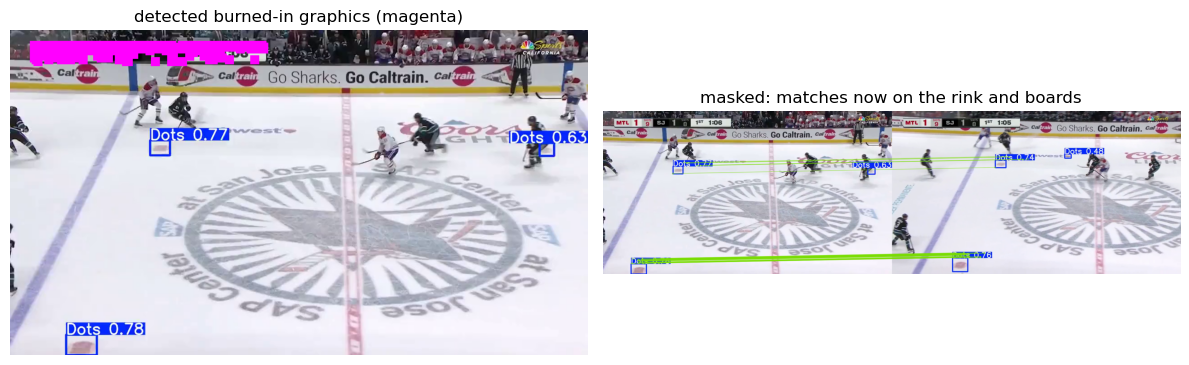

In [6]:
from rinkiq.camera import static_overlay_mask
overlay, fixed_camera = static_overlay_mask(clip)
keep = None if overlay is None else (~overlay).astype(np.uint8) * 255   # 255 = "look for keypoints here"
on_graphics = 0 if overlay is None else int(overlay[src_naive[:, 1].astype(int), src_naive[:, 0].astype(int)].sum())
shift, n_in, n_m, vis, _ = camera_motion(keep)
print(f"without the mask, {on_graphics} of the 60 matches sat on graphics")
print(f"with the mask: {n_in} of {n_m} matches agree · they moved {shift:+.0f} px sideways (median)")
print("Here the rink matches out-voted the graphics either way. The mask is insurance for clips where they wouldn't.")
show([np.where(overlay[..., None], [255, 0, 255], rgb(f0)).astype(np.uint8) if overlay is not None else rgb(f0), rgb(vis)],
     ["detected burned-in graphics (magenta)", "masked: matches now on the rink and boards"], 6)

## ⑤ Pixels → rink feet: the homography
The ice is flat, so one 3×3 matrix maps the picture onto a top-down rink. Five hand-checked landmarks solve it.
Then we nudge one landmark by 20 px. With a **spare** landmark (5 for 4 needed) the fit barely notices, because the other points out-vote the bad one. Delete one entry from `pts` and re-run to see how quickly errors grow **far away** when every point is load-bearing.

homography matrix H:
 [[   0.065813     0.12627      53.436]
 [  0.0025163    -0.10806      114.34]
 [  2.861e-05   0.0012884           1]]
mean error at the landmarks: 0.2 ft


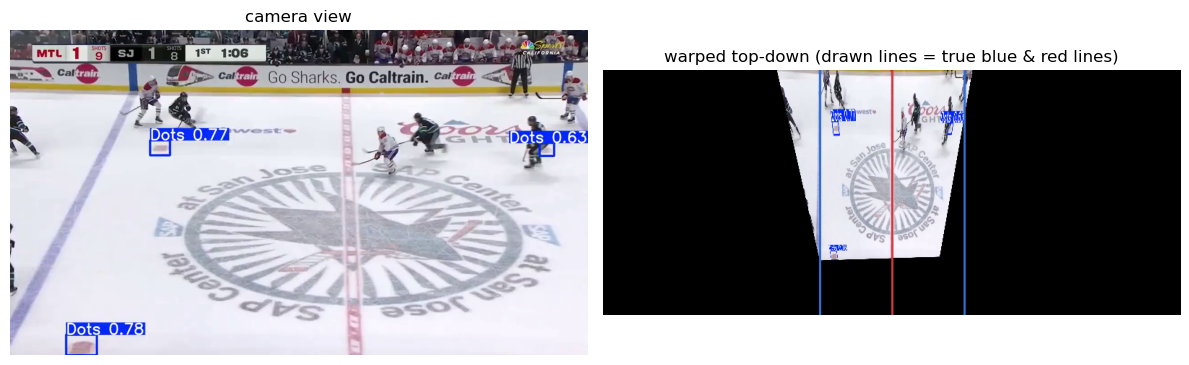

mis-click one landmark by  0 px → error at the far end-zone dot:  0.0 ft
mis-click one landmark by 10 px → error at the far end-zone dot:  0.1 ft
mis-click one landmark by 20 px → error at the far end-zone dot:  0.3 ft


In [7]:
pts = models.SAMPLE_CALIBRATION[CLIP]
cal = Calibration.from_pairs([((x, y), n) for x, y, n in pts])
print("homography matrix H:\n", np.array2string(cal.H, precision=4, suppress_small=True))
print(f"mean error at the landmarks: {cal.reprojection_error_ft():.1f} ft")

S = 4
T = np.array([[S, 0, 0], [0, -S, RINK_WIDTH * S], [0, 0, 1]])
top = cv2.warpPerspective(f0, T @ cal.H, (int(RINK_LENGTH * S), int(RINK_WIDTH * S)))
for xl, col in [(75, (214, 111, 47)), (125, (214, 111, 47)), (100, (62, 57, 208))]:
    cv2.line(top, (xl * S, 0), (xl * S, int(RINK_WIDTH * S)), col, 2)
show([rgb(f0), rgb(top)], ["camera view", "warped top-down (drawn lines = true blue & red lines)"], 6)

truth = np.array(LANDMARKS["End-zone dot · left · far"])
far_px = pixels_to_rink(np.array([truth]), np.linalg.inv(cal.H))
for nudge in [0, 10, 20]:
    bad = Calibration.from_pairs([((x + (nudge if i == 0 else 0), y), n) for i, (x, y, n) in enumerate(pts)])
    err = np.linalg.norm(pixels_to_rink(far_px, bad.H)[0] - truth)
    print(f"mis-click one landmark by {nudge:2d} px → error at the far end-zone dot: {err:4.1f} ft")

## ⑥ From positions to speed: smoothing noisy data
A simulated skater with known true speed, plus detection jitter. Raw differences explode, smoothing fixes it,
and over-smoothing flattens real sprints (the bias–variance trade-off).

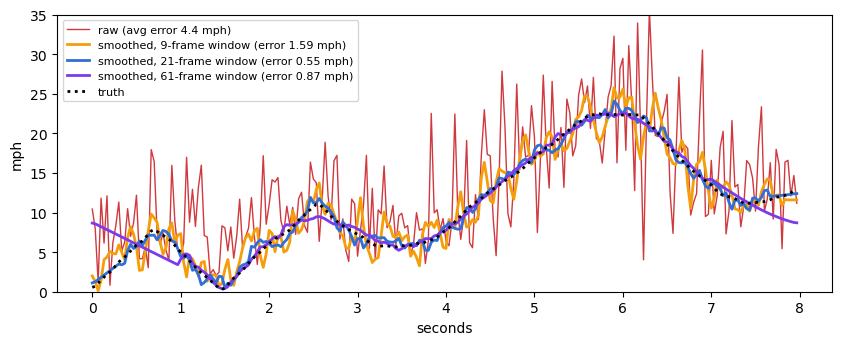

In [8]:
clean, _, _ = simulate.simulate_game(seconds=8, pixel_noise_ft=0.0, puck_dropout=0)
noisy, _, _ = simulate.simulate_game(seconds=8, pixel_noise_ft=0.4, puck_dropout=0)
g0, g = clean[clean.track_id == 1].sort_values("t"), noisy[noisy.track_id == 1].sort_values("t")
t = g.t.to_numpy()
mph = lambda x, y: np.hypot(np.gradient(x, t), np.gradient(y, t)) * 0.6818
true = mph(g0.x.to_numpy(), g0.y.to_numpy())
raw = mph(g.x.to_numpy(), g.y.to_numpy())
plt.figure(figsize=(10, 3.6))
plt.plot(t, raw, c="#d0393e", lw=1, label=f"raw (avg error {np.mean(np.abs(raw - true)):.1f} mph)")
for w, c in [(9, "#f59e0b"), (21, "#2f6fd6"), (61, "#7c3aed")]:
    sm = mph(savgol_filter(g.x, w, 2), savgol_filter(g.y, w, 2))
    plt.plot(t, sm, c=c, lw=2, label=f"smoothed, {w}-frame window (error {np.mean(np.abs(sm - true)):.2f} mph)")
plt.plot(t, true, "k:", lw=2, label="truth"); plt.ylim(0, 35); plt.ylabel("mph"); plt.xlabel("seconds"); plt.legend(fontsize=8); plt.show()

## ⑦ Body pose: which way is a player facing?
The pose model finds 17 keypoints per player. Shoulders and hips give a facing direction.

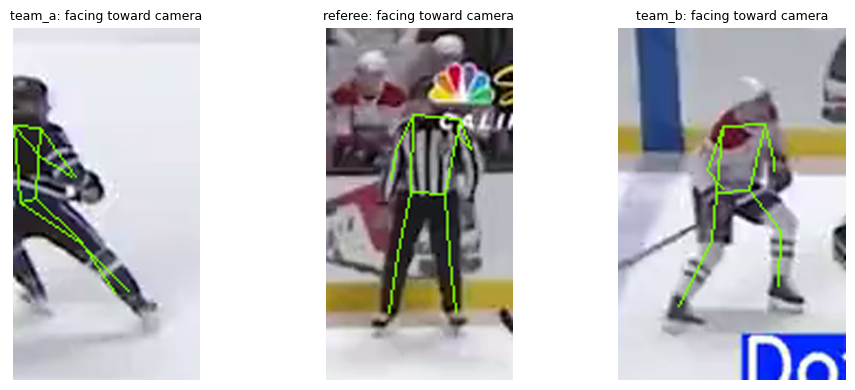

Players are only ~60–100 px tall on broadcast TV, so keypoints are rough. RinkIQ only uses them for a coarse stat.


In [9]:
good = det[det.conf >= 0.3].sort_values("conf", ascending=False).reset_index(drop=True)
shown = 0
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for _, r in good.iterrows():
    out = pipeline._pose_on_crops(f0, np.array([[r.x1, r.y1, r.x2, r.y2]]))[0]
    if out is None:
        continue
    k, c = out
    pad = 20; x1, y1 = int(max(0, r.x1 - pad)), int(max(0, r.y1 - pad))
    crop = f0[y1:int(r.y2 + pad), x1:int(r.x2 + pad)].copy(); k = k - np.array([x1, y1])
    for a_, b_ in [(5, 6), (5, 11), (6, 12), (11, 12), (5, 7), (7, 9), (6, 8), (8, 10), (11, 13), (13, 15), (12, 14), (14, 16)]:
        if c[a_] > 0.3 and c[b_] > 0.3:
            cv2.line(crop, tuple(k[a_].astype(int)), tuple(k[b_].astype(int)), (0, 255, 120), 1)
    est = facing_from_keypoints(k, c)
    facing = "unclear" if est is None else ("toward camera" if est[0][1] > 0.3 else "away from camera" if est[0][1] < -0.3 else ("right" if est[0][0] > 0 else "left"))
    axes[shown].imshow(rgb(cv2.resize(crop, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)))
    axes[shown].set_title(f"{r.label.replace('_player', '')}: facing {facing}", fontsize=9); axes[shown].axis("off")
    shown += 1
    if shown == 3:
        break
plt.tight_layout(); plt.show()
print("Players are only ~60–100 px tall on broadcast TV, so keypoints are rough. RinkIQ only uses them for a coarse stat.")

## ✅ How do we know the numbers are right? Validation against ground truth
Simulate a 20-second game where we **know** every true speed, pass and shot, run the full stats pipeline,
and compare.

In [10]:
players, puck, meta = simulate.simulate_game()
res = analyze(players, puck, meta)
s = res["summary"].set_index("track_id")
cmp = pd.DataFrame([(tid, true, s.loc[tid, "top_speed_mph"]) for tid, true in meta["truth"]["top_speed_mph"].items()],
                   columns=["track", "true top speed", "measured"]).round(1)
cmp["error"] = (cmp["measured"] - cmp["true top speed"]).round(1)
print(f"mean absolute top-speed error: {cmp.error.abs().mean():.2f} mph across {len(cmp)} skaters")
print("cheating winger flagged as out of position:", meta["truth"]["cheater"] in set(res["review"]["track_id"]))
cmp.head(10)

mean absolute top-speed error: 0.42 mph across 10 skaters
cheating winger flagged as out of position: True


,track,true top speed,measured,error
0,1,22.4,22.6,0.2
1,2,23.4,24.1,0.7
2,3,20.1,20.2,0.1
3,4,20.7,21.7,1.0
4,5,21.0,21.6,0.6
5,6,23.4,24.3,0.9
6,7,19.9,19.9,0.0
7,8,22.1,22.5,0.4
8,9,23.1,23.4,0.3
9,10,16.9,16.9,0.0


## 🎉 You've seen every step
**Next:** `streamlit run app.py` → **🎓 Learn CV** tab for the same steps with sliders, then **① Film** to run the
full pipeline on a clip.